# Kanz | كنز
### Machine Learning Project — Tuwaiq Academy

## 1. Problem Definition

Marine ecosystems face rising ocean temperatures and coral bleaching, while many marine species remain undiscovered.

Kanz uses machine learning to explore five questions:

1. **Where is marine biodiversity?** — Model 1: Treasure Map.
2. **What threatens coral reefs?** — Model 2: Bleaching Risk.
3. **Where is biodiversity most at risk today?** — Combines both models with current heat data.
4. **Which areas need attention?** — Identifies vulnerable locations.
5. **Where can people dive responsibly?** — Reef Health Index.

### Machine Learning Tasks

- **Model 1 — Regression:** Estimates species richness in ocean areas.
- **Model 2 — Classification:** Predicts bleaching severity: none, mild, or severe.
- **Reef Health Index:** Scores dive sites using available environmental data.


* Why care? Around 8,896 new marine species were described in the 2010s, and 18.9% of species were recorded only once.

* Discover: Warm seas (above 20°C) contain 3× more species than cold seas (503 vs. 169 median species).

* Danger: Severe coral bleaching increases from 12.7% without heat stress to 58.6% under extreme heat stress (DHW 8+). Reefs without coral also have 3× fewer fish species (15 vs. 49).

* At Risk: 72 of 214 reef regions (33.6%) are under bleaching alert, including Jazan (DHW 17.5). However, severe bleaching in Red Sea corals is much lower (2.1% vs. 56.4%).

* Dive & Act: 316 threatened species live near 149 top dive sites, including the critically endangered hawksbill turtle, found near 49% of them.

In [37]:
#import libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.base import clone
from sklearn.model_selection import GroupKFold, cross_validate, cross_val_predict, RandomizedSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier, BallTree
from sklearn.ensemble import (RandomForestRegressor, RandomForestClassifier,
                              HistGradientBoostingRegressor, HistGradientBoostingClassifier, VotingClassifier)
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score, recall_score, make_scorer, ConfusionMatrixDisplay
from sklearn.calibration import calibration_curve

# works inside the project (notebooks/) and inside the shared zip folder
DATA = "../datasets_csv/" if os.path.exists("../datasets_csv") else "datasets_csv/"

In [ ]:
#2. Data
bleaching = pd.read_csv(DATA + "coral_bleaching_surveys.csv.gz", na_values=["nd"], low_memory=False)
stations = pd.read_csv(DATA + "noaa_reef_stations.csv")
heat = pd.read_csv(DATA + "noaa_reef_heat_stress_daily.csv.gz")
surveys = pd.read_csv(DATA + "reef_life_surveys.csv")
sites = pd.read_csv(DATA + "reef_life_sites.csv")
animals = pd.read_csv(DATA + "obis_marine_animal_species.csv.gz", low_memory=False)
grid = pd.read_csv(DATA + "ocean_grid_cells.csv")
threatened = pd.read_csv(DATA + "threatened_species_near_dive_sites.csv")
corals = pd.read_csv(DATA + "deep_sea_corals_species.csv")
sst_trend = pd.read_csv(DATA + "sea_temperature_anomaly.csv")

In [39]:
tables = {"bleaching": bleaching, "stations": stations, "heat": heat, "surveys": surveys, "sites": sites,
          "animals": animals, "grid": grid, "threatened": threatened, "corals": corals, "sst_trend": sst_trend}
pd.DataFrame({"rows": [len(t) for t in tables.values()],
              "columns": [t.shape[1] for t in tables.values()]}, index=tables.keys())

,rows,columns
bleaching,41361,62
stations,214,4
heat,156220,11
surveys,36447,9
sites,4894,12
animals,164232,11
grid,1881,12
threatened,5019,5
corals,4384,8
sst_trend,531,6


Species seen only once: 18.9 %


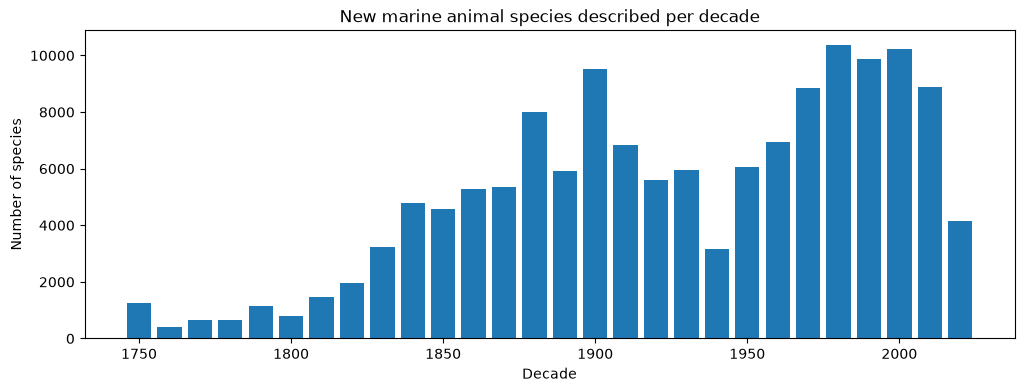

In [40]:
#3 EDA
#3.1 discovery curve: are we still finding new species?
species = animals[animals["taxonRank"] == "Species"].copy()
species["year"] = species["scientificNameAuthorship"].str.extract(r"(1[789]\d\d|20\d\d)").astype(float)
per_decade = (species["year"] // 10 * 10).value_counts().sort_index()

print("Species seen only once:", round((species["records"] == 1).mean() * 100, 1), "%")
plt.figure(figsize=(12, 4))
plt.bar(per_decade.index, per_decade.values, width=8)
plt.title("New marine animal species described per decade")
plt.xlabel("Decade")
plt.ylabel("Number of species")
plt.show()

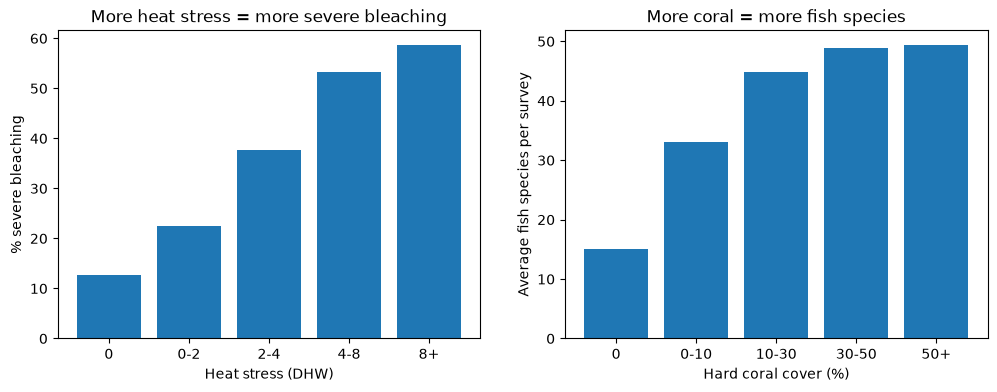

In [41]:
#3.2 heat -> bleaching, and coral -> fish
samples = bleaching[bleaching["Percent_Bleaching"].notna()].drop_duplicates("Sample_ID")
dhw_group = pd.cut(samples["TSA_DHW"], bins=[-0.1, 0, 2, 4, 8, 100], labels=["0", "0-2", "2-4", "4-8", "8+"])
severe_by_heat = (samples["Percent_Bleaching"] >= 20).groupby(dhw_group, observed=True).mean() * 100

coral_group = pd.cut(surveys["hard_coral_pct"], bins=[-0.1, 0, 10, 30, 50, 100], labels=["0", "0-10", "10-30", "30-50", "50+"])
fish_by_coral = surveys.groupby(coral_group, observed=True)["fish_species"].mean()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(severe_by_heat.index.astype(str), severe_by_heat.values)
ax[0].set_title("More heat stress = more severe bleaching")
ax[0].set_xlabel("Heat stress (DHW)")
ax[0].set_ylabel("% severe bleaching")
ax[1].bar(fish_by_coral.index.astype(str), fish_by_coral.values)
ax[1].set_title("More coral = more fish species")
ax[1].set_xlabel("Hard coral cover (%)")
ax[1].set_ylabel("Average fish species per survey")
plt.show()

In [42]:
#3.3 the Red Sea twist + sampling bias
red_sea = samples["Ecoregion_Name"].str.contains("Red Sea|Gulf of Aden", na=False)
hot = samples["TSA_DHW"] >= 4
print("Severe bleaching under strong heat -> Red Sea:",
      round((samples.loc[hot & red_sea, "Percent_Bleaching"] >= 20).mean() * 100, 1), "% | rest of world:",
      round((samples.loc[hot & ~red_sea, "Percent_Bleaching"] >= 20).mean() * 100, 1), "%")

print("Correlation log(records) vs log(species):",
      round(np.log1p(grid["obis_records"]).corr(np.log1p(grid["obis_species"])), 2))
print("Dive sites in Australia:", round((sites["country"] == "Australia").mean() * 100, 1), "%")

Severe bleaching under strong heat -> Red Sea: 2.1 % | rest of world: 56.4 %
Correlation log(records) vs log(species): 0.83
Dive sites in Australia: 57.5 %


### Key Findings

- Species discovery continues: 8,896 new species were described in the 2010s; 18.9% were recorded only once.
- Severe bleaching rises from 12.7% with no heat stress to 58.6% at DHW 8+.
- Average fish diversity rises from 15 species with no coral cover to 49.4 at 50%+ coral cover.
- Under strong heat, severe bleaching was 2.1% in the Red Sea versus 56.4% elsewhere.
- Bleaching classes: 39.6% none, 39.0% mild, and 21.4% severe.
- Data gaps: 17.4% of bleaching rows contain a fake ClimSST value (-11°C); only 13.6% of dive surveys recorded coral percentage.
- Sampling is uneven: species records correlate with search effort (0.83), and 57.5% of dive sites are in Australia.

### Modeling Implications

- Class imbalance makes macro F1 and severe recall more useful than accuracy.
- Grouped splits test on unseen ocean regions (Model 1) and reef sites (Model 2), reducing overly optimistic results.
- Heat alone is insufficient (maximum correlation = 0.28), so the models combine multiple features.

In [43]:
#4. preprocessing
#4.1 ocean grid (Model 1)

#1- log because records go from 1 to 25 million
grid["log_records"] = np.log1p(grid["obis_records"])
grid["log_species"] = np.log1p(grid["obis_species"])

#2- distance from the equator (north and south are alike)
grid["abs_lat"] = grid["cell_lat"].abs()

#3- 30° blocks for spatial CV (test on whole ocean regions the model never saw)
grid["block"] = (grid["cell_lat"] // 30).astype(int).astype(str) + "_" + (grid["cell_lon"] // 30).astype(int).astype(str)

FEATURES1 = ["log_records", "abs_lat", "ocean_frac", "shelf_frac", "depth_mean", "depth_max",
             "sst_mean", "sst_min", "sst_max", "sst_range"]
X1 = grid[FEATURES1]
y1 = grid["log_species"]
groups1 = grid["block"]

print("Ocean cells:", len(grid), "| 30° blocks:", groups1.nunique())

Ocean cells: 1881 | 30° blocks: 71


In [44]:

#4.2 bleaching data (Model 2)

#1- fake temperature (262.15 K = -11 °C) -> missing
bleaching.loc[bleaching["ClimSST"] == 262.15, "ClimSST"] = np.nan

#2- one row per sample (each sample is repeated once per seabed type)
df = bleaching[bleaching["Percent_Bleaching"].notna()].drop_duplicates("Sample_ID").reset_index(drop=True)

#3- target: 0 none / 1 mild (<20%) / 2 severe (>=20%)
df["target"] = np.select([df["Percent_Bleaching"] == 0, df["Percent_Bleaching"] < 20], [0, 1], default=2)

#4- inputs: 12 "current" columns (the ones we can also build from today's NOAA data)
CURRENT = ["Temperature_Kelvin", "SSTA", "TSA", "SSTA_DHW", "TSA_DHW", "Date_Month",                  # heat now + month
           "ClimSST", "Depth_m", "Distance_to_Shore", "Turbidity", "Cyclone_Frequency", "Windspeed"]  # the place

#all numeric columns (only to compare with)
not_features = ["Site_ID", "Sample_ID", "Percent_Bleaching", "Percent_Cover", "target",
                "Latitude_Degrees", "Longitude_Degrees", "Date_Day", "Date_Year"]
ALL = [c for c in df.select_dtypes("number").columns if c not in not_features]

X2 = df[CURRENT]
y2 = df["target"]
groups2 = df["Site_ID"]   # GroupKFold: test on reef sites the model never saw

print("Samples:", len(df), "| reef sites:", groups2.nunique())
print("Current columns:", len(CURRENT), "| all columns:", len(ALL))
print("Missing ClimSST:", X2["ClimSST"].isna().sum())

Samples: 23271 | reef sites: 11068
Current columns: 12 | all columns: 38
Missing ClimSST: 4229


In [45]:
#4.3 dive sites (Dive Finder)
EARTH_KM = 6371

#1- one row per site: the average of all its dives
site_stats = surveys.groupby("site_code").agg(
    dives=("survey_id", "size"),
    fish_species=("fish_species", "mean"),
    hard_coral=("hard_coral_pct", "mean"),
    visibility=("visibility", "mean"))
dive_sites = sites.merge(site_stats, left_on="site_code", right_index=True, how="inner")

#2- keep sites with 3+ dives (one lucky dive should not win)
dive_sites = dive_sites[dive_sites["dives"] >= 3].reset_index(drop=True)
print("Dive sites with 3+ dives:", len(dive_sites))

Dive sites with 3+ dives: 2648


In [ ]:
#3- bleaching history: average bleaching % of surveys within 50 km
#BallTree + haversine = fast distance search on a round Earth (needs radians)
site_rad = np.radians(dive_sites[["latitude", "longitude"]])
bleach_tree = BallTree(np.radians(df[["Latitude_Degrees", "Longitude_Degrees"]]), metric="haversine")
near_bleach = bleach_tree.query_radius(site_rad, r=50 / EARTH_KM)

bleach_pct = df["Percent_Bleaching"].to_numpy()
dive_sites["bleach_history"] = [bleach_pct[i].mean() if len(i) > 0 else np.nan for i in near_bleach]

#4- nearest NOAA station within 300 km (its risk today is added in section 8)
station_tree = BallTree(np.radians(stations[["lat", "lon"]]), metric="haversine")
dist, nearest = station_tree.query(site_rad, k=1)
dive_sites["station"] = stations["station"].to_numpy()[nearest[:, 0]]
dive_sites["station_km"] = (dist[:, 0] * EARTH_KM).round(0)
dive_sites.loc[dive_sites["station_km"] > 300, "station"] = np.nan

print("Sites with bleaching surveys within 50 km:", dive_sites["bleach_history"].notna().sum())
print("Sites with a NOAA station within 300 km:", dive_sites["station"].notna().sum())
print("Sites with no coral data %:", round(dive_sites["hard_coral"].isna().mean() * 100, 1), "%")

Sites with bleaching surveys within 50 km: 660
Sites with a NOAA station within 300 km: 1142
Sites with no coral %: 50.0 %


Why we chose this approach

1. One row per sample: Removed duplicates to prevent the same sample appearing in both training and testing, leaving 23,271 samples from 11,068 reef sites.

2. Missing temperatures were kept: 4,229 fake temperature values (−11°C) were treated as missing rather than deleting the samples. Missing values are filled using training data only.

3. Three bleaching classes: Samples were classified as none (0%), mild (<20%), or severe (≥20%).

4. 12 current features: Selected because they can be obtained from today's NOAA data and compared against all 38 features.

5. No one-hot encoding: All 12 features are numerical, so encoding categorical variables was unnecessary.

6. Grid adjustments: Log transformation handles large differences in record counts, distance from the equator accounts for similar northern and southern patterns, and 30° blocks allow testing on unseen regions.

7. Dive-site selection: Sites with at least 3 dives were retained for reliability. Distances of 50 km and 300 km represent local reef and regional NOAA coverage. Areas without monitoring receive a neutral score rather than an unreliable prediction.

In [47]:
# 5. Modeles
#5.1 Model 1 — Treasure Map (regression): predict log(species) of each ocean cell
models1 = {
    "Effort only (baseline)": make_pipeline(LinearRegression()),   # uses only log_records
    "Ridge": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=1.0)),
    "Random Forest": make_pipeline(SimpleImputer(strategy="median"),
                                   RandomForestRegressor(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=42)),
    "Gradient Boosting": make_pipeline(SimpleImputer(strategy="median"), HistGradientBoostingRegressor(random_state=42)),
}

In [48]:
#5.2 Model 2 — Bleaching risk (classification): 0 none / 1 mild / 2 severe

#baseline 1: heat rule (NOAA alert level): DHW 0 -> none, 0-4 -> mild, 4+ -> severe
def heat_rule(dhw):
    dhw = dhw.fillna(0)
    return np.select([dhw <= 0, dhw < 4], [0, 1], default=2)

models2 = {
    "Most common (baseline)": make_pipeline(SimpleImputer(strategy="median"), DummyClassifier(strategy="most_frequent")),
    "Logistic Regression": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                                         LogisticRegression(max_iter=2000, class_weight="balanced")),
    "KNN": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), KNeighborsClassifier(n_neighbors=15)),
    "Random Forest": make_pipeline(SimpleImputer(strategy="median"),
                                   RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced",
                                                          n_jobs=-1, random_state=42)),
    "Gradient Boosting": make_pipeline(SimpleImputer(strategy="median"),
                                       HistGradientBoostingClassifier(class_weight="balanced", random_state=42)),
    "Voting": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), VotingClassifier([
        ("lr", LogisticRegression(max_iter=2000, class_weight="balanced")),
        ("knn", KNeighborsClassifier(n_neighbors=15)),
        ("rf", RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced", n_jobs=-1, random_state=42)),
        ("gb", HistGradientBoostingClassifier(class_weight="balanced", random_state=42))], voting="soft")),
}

### Model Choices

- **Baselines:** Effort Only and the NOAA Heat Rule provide simple reference points.
- **Ridge and Logistic Regression:** Simple, interpretable linear models.
- **KNN:** Tests whether environmentally similar reefs have similar bleaching patterns.
- **Random Forest and Gradient Boosting:** Capture nonlinear relationships and feature interactions.
- **Voting:** Combines four classifiers using soft voting.
- **Balanced class weights:** Address the 21.4% severe-bleaching class.
- **Pipelines:** Fit imputation and scaling on training folds only, preventing data leakage.

In [49]:
# 6. Evaluation
#6.1 Model 1: spatial-block CV (5 folds, whole 30° ocean regions are held out)
cv1 = GroupKFold(n_splits=5)

rows = []
for name, model in models1.items():
    cols = ["log_records"] if "baseline" in name else FEATURES1
    r = cross_validate(model, X1[cols], y1, groups=groups1, cv=cv1,
                       scoring={"r2": "r2", "mae": "neg_mean_absolute_error"})
    rows.append([name, r["test_r2"].mean(), r["test_r2"].std(), -r["test_mae"].mean()])

results1 = pd.DataFrame(rows, columns=["model", "mean", "std", "MAE (log)"]).set_index("model")   # mean / std = R²
results1.round(3)

,mean,std,MAE (log)
model,,,
Effort only (baseline),0.682,0.037,0.657
Ridge,0.815,0.023,0.501
Random Forest,0.816,0.020,0.493
Gradient Boosting,0.814,0.020,0.502


In [50]:
#6.2 Model 1 sanity check
#expected species = what the model predicts if a cell were searched like a well-searched cell
#in the best-searched cells (top 10%), expected should be ≈ recorded
best_sampled = grid["log_records"] >= grid["log_records"].quantile(0.90)
WELL = grid.loc[best_sampled, "log_records"].median()   # effort of a well-searched cell
MAX = grid["log_records"].max()                           # the most searched cell in the world
print("Well-searched cell:", int(np.expm1(WELL)), "records | most searched cell:", int(np.expm1(MAX)), "records")

def expected_gap(model, cols, effort):
    """median % gap (expected vs recorded) in the best-searched cells, predicted on unseen regions"""
    expected = np.zeros(len(grid))
    for train, test in cv1.split(X1, y1, groups1):
        m = clone(model).fit(X1.iloc[train][cols], y1.iloc[train])
        X_test = X1.iloc[test][cols].copy()
        X_test["log_records"] = effort
        expected[test] = np.expm1(m.predict(X_test))
    gap = expected / grid["obis_species"] - 1
    return round(gap[best_sampled].median() * 100, 1)

Well-searched cell: 373261 records | most searched cell: 25731698 records


In [51]:
rows = []
for name, model in models1.items():
    cols = ["log_records"] if "baseline" in name else FEATURES1
    rows.append([name, expected_gap(model, cols, WELL), expected_gap(model, cols, MAX)])

sanity = pd.DataFrame(rows, columns=["model", "well-searched (%)", "max search (%)"]).set_index("model")

#pass = close to recorded (±25%) AND does not explode with more searching (≤ +100%)
sanity["passed"] = (sanity["well-searched (%)"].abs() <= 25) & (sanity["max search (%)"] <= 100)
sanity

,well-searched (%),max search (%),passed
model,,,
Effort only (baseline),-13.6,870.7,False
Ridge,5.7,711.6,False
Random Forest,-9.6,32.4,True
Gradient Boosting,-11.8,41.2,True


In [52]:
#6.3 Model 2: GroupKFold by reef site (5 folds, test sites never seen in training) — takes ~2 minutes
cv2 = GroupKFold(n_splits=5)
scoring2 = {"macro_f1": "f1_macro",
            "severe_recall": make_scorer(recall_score, labels=[2], average="macro")}

#heat rule (no training needed)
rule = heat_rule(df["TSA_DHW"])
rows = [["Heat rule (baseline)", f1_score(y2, rule, average="macro"), 0.0,
         recall_score(y2, rule, labels=[2], average="macro")]]

for name, model in models2.items():
    r = cross_validate(model, X2, y2, groups=groups2, cv=cv2, scoring=scoring2)
    rows.append([name, r["test_macro_f1"].mean(), r["test_macro_f1"].std(), r["test_severe_recall"].mean()])

results2 = pd.DataFrame(rows, columns=["model", "mean", "std", "severe recall"]).set_index("model")   # mean / std = macro F1
results2.round(3)

,mean,std,severe recall
model,,,
Heat rule (baseline),0.425,0.000,0.305
Most common (baseline),0.189,0.004,0.000
Logistic Regression,0.485,0.005,0.576
KNN,0.633,0.015,0.549
Random Forest,0.682,0.009,0.751
Gradient Boosting,0.677,0.005,0.752
Voting,0.684,0.010,0.725


In [53]:
#6.4 12 current columns vs all 38, and the future-years test
#future test: train on years <= 2010, test on years after 2010 (the real use = predicting the future)
past = df["Date_Year"] <= 2010
future = df["Date_Year"] > 2010

def future_test(model, cols):
    m = clone(model).fit(df.loc[past, cols], y2[past])
    pred = m.predict(df.loc[future, cols])
    return f1_score(y2[future], pred, average="macro"), recall_score(y2[future], pred, labels=[2], average="macro")

rf = models2["Random Forest"]
rf_all = cross_validate(rf, df[ALL], y2, groups=groups2, cv=cv2, scoring=scoring2)
f_current = future_test(rf, CURRENT)
f_all = future_test(rf, ALL)
f_rule = (f1_score(y2[future], rule[future], average="macro"),
          recall_score(y2[future], rule[future], labels=[2], average="macro"))

compare = pd.DataFrame({
    "unseen sites F1": [results2.loc["Random Forest", "mean"], rf_all["test_macro_f1"].mean(),
                        results2.loc["Heat rule (baseline)", "mean"]],
    "future years F1": [f_current[0], f_all[0], f_rule[0]],
    "future severe recall": [f_current[1], f_all[1], f_rule[1]]},
    index=[f"Random Forest ({len(CURRENT)} current columns)", f"Random Forest (all {len(ALL)} columns)", "Heat rule"])

print("Past samples:", past.sum(), "| future samples:", future.sum())
compare.round(3)

Past samples: 15793 | future samples: 7478


,unseen sites F1,future years F1,future severe recall
Random Forest (12 current columns),0.682,0.505,0.290
Random Forest (all 38 columns),0.719,0.426,0.050
Heat rule,0.425,0.466,0.334


Why we chose these models

1. Model 1 is reliable: Tested on unseen ocean regions, Random Forest achieved R² = 0.816, with Ridge and Gradient Boosting performing similarly.

2. Predictions are realistic: All models accurately estimate species numbers in the most frequently searched areas.

3. Random Forest is more realistic: Unlike Ridge, which predicts unlimited species growth, Random Forest accounts for the fact that discoveries eventually level off.

4. Model 2 generalizes well: Tested on unseen reef sites, tree-based models outperformed the heat rule, especially in detecting severe bleaching.

5. We chose 12 features instead of 38: Although 38 features performed better on unseen sites, 12 performed better on future-year predictions and detected more severe bleaching. They can also be obtained from current NOAA data.

6. Future predictions have limitations: The heat rule slightly outperformed the model in detecting future severe bleaching. Changes in data sources and lower severe-bleaching rates after 2010 likely explain this.

In [54]:
#7. modle selection
#7.1 apply the rule
def select_model(results, baseline_score, simple_to_complex, passed=None):
    #1 it must beat its baseline
    ok = results[results["mean"] > baseline_score]
    #4 (Model 1 only) it must pass the sanity check
    if passed is not None:
        ok = ok[[passed[m] for m in ok.index]]
    #2 best cross-validated score
    best = ok["mean"].idxmax()
    #3 a simpler model within 1 std of the best -> take the simpler one
    limit = ok.loc[best, "mean"] - ok.loc[best, "std"]
    for m in simple_to_complex:
        if m in ok.index and ok.loc[m, "mean"] >= limit:
            return m

winner1 = select_model(results1, results1.loc["Effort only (baseline)", "mean"],
                       ["Ridge", "Random Forest", "Gradient Boosting"], passed=sanity["passed"])
winner2 = select_model(results2, results2.loc["Heat rule (baseline)", "mean"],
                       ["Logistic Regression", "KNN", "Random Forest", "Gradient Boosting", "Voting"])
print("Model 1 winner:", winner1)
print("Model 2 winner:", winner2)

Model 1 winner: Random Forest
Model 2 winner: Random Forest


In [55]:
#7.2 tune Model 1 (winner = Random Forest)
search1 = RandomizedSearchCV(models1["Random Forest"], {
    "randomforestregressor__n_estimators": [300, 500],
    "randomforestregressor__min_samples_leaf": [1, 2, 3, 5],
    "randomforestregressor__max_features": [1.0, 0.5, "sqrt"]},
    n_iter=10, scoring="r2", cv=cv1, random_state=42)
search1.fit(X1, y1, groups=groups1)
model1 = search1.best_estimator_

print("Best settings:", search1.best_params_)
print("R²:", round(search1.best_score_, 3), "±", round(search1.cv_results_["std_test_score"][search1.best_index_], 3))
print("Sanity check -> well-searched:", expected_gap(model1, FEATURES1, WELL), "% | max search:", expected_gap(model1, FEATURES1, MAX), "%")

Best settings: {'randomforestregressor__n_estimators': 500, 'randomforestregressor__min_samples_leaf': 2, 'randomforestregressor__max_features': 0.5}
R²: 0.82 ± 0.018
Sanity check -> well-searched: -17.0 % | max search: 11.7 %


In [ ]:
#tune Model 2 (winner = Random Forest) 
search2 = RandomizedSearchCV(models2["Random Forest"], {
    "randomforestclassifier__n_estimators": [200, 300],
    "randomforestclassifier__min_samples_leaf": [1, 2, 5, 10],
    "randomforestclassifier__max_features": ["sqrt", 0.5]},
    n_iter=6, scoring="f1_macro", cv=cv2, random_state=42)
search2.fit(X2, y2, groups=groups2)
model2 = search2.best_estimator_

print("Best settings:", search2.best_params_)
print("Macro F1:", round(search2.best_score_, 3), "±", round(search2.cv_results_["std_test_score"][search2.best_index_], 3))

Best settings: {'randomforestclassifier__n_estimators': 200, 'randomforestclassifier__min_samples_leaf': 1, 'randomforestclassifier__max_features': 'sqrt'}
Macro F1: 0.703 ± 0.009


Macro F1: 0.703 | severe recall: 0.721


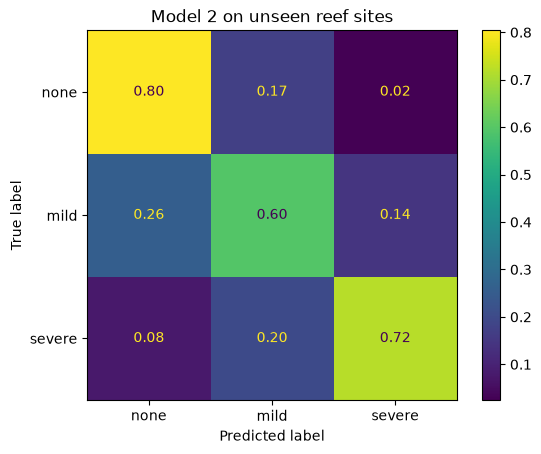

In [57]:
#7.3 final checks of Model 2 on unseen sites: confusion matrix
proba = cross_val_predict(model2, X2, y2, groups=groups2, cv=cv2, method="predict_proba")
pred = proba.argmax(axis=1)
print("Macro F1:", round(f1_score(y2, pred, average="macro"), 3),
      "| severe recall:", round(recall_score(y2, pred, labels=[2], average="macro"), 3))

ConfusionMatrixDisplay.from_predictions(y2, pred, normalize="true", values_format=".2f",
                                        display_labels=["none", "mild", "severe"])
plt.title("Model 2 on unseen reef sites")
plt.show()

In [58]:
#calibration: when the model says "70% severe", is it really severe ~70% of the time?
actual, predicted = calibration_curve(y2 == 2, proba[:, 2], n_bins=5)
pd.DataFrame({"model says (severe)": predicted.round(2), "really severe": actual.round(2)})

,model says (severe),really severe
0,0.07,0.04
1,0.29,0.22
2,0.50,0.47
3,0.70,0.73
4,0.91,0.88


Future years -> macro F1: 0.5 | severe recall: 0.265


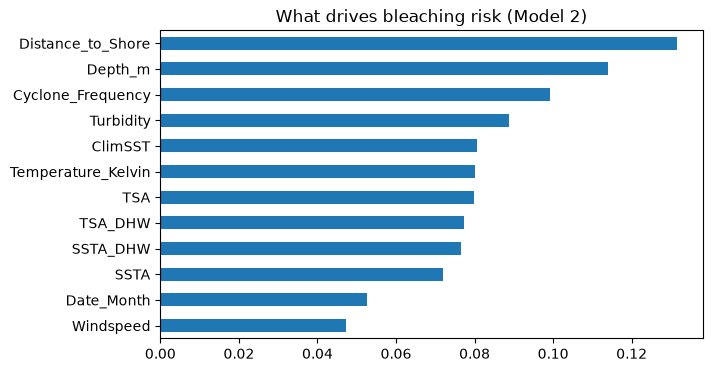

In [59]:
#future years with the tuned model + top features
f_final = future_test(model2, CURRENT)
print("Future years -> macro F1:", round(f_final[0], 3), "| severe recall:", round(f_final[1], 3))

importance = pd.Series(model2[-1].feature_importances_, index=CURRENT).sort_values()
importance.plot.barh(figsize=(7, 4), title="What drives bleaching risk (Model 2)")
plt.show()

In [60]:
#7.4 results table
final = pd.DataFrame({
    "model": ["Model 1 — Treasure Map", "Model 2 — Bleaching risk"],
    "chosen": [f"{winner1} (tuned)", f"{winner2} (tuned)"],
    "test": ["unseen ocean regions (30° blocks)", "unseen reef sites"],
    "score": [f"R^2 {search1.best_score_:.2f}", f"macro F1 {search2.best_score_:.2f}"],
    "baseline": [f"effort only {results1.loc['Effort only (baseline)', 'mean']:.2f}",
                 f"heat rule {results2.loc['Heat rule (baseline)', 'mean']:.2f}"]})
final

,model,chosen,test,score,baseline
0,Model 1 — Treasure Map,Random Forest (tuned),unseen ocean regions (30° blocks),R^2 0.82,effort only 0.68
1,Model 2 — Bleaching risk,Random Forest (tuned),unseen reef sites,macro F1 0.70,heat rule 0.43


### Model Selection and Evaluation

1. **Model 1 — Random Forest:** All models beat the 0.68 baseline. Ridge fails the sanity check; Random Forest scores 0.816. Gradient Boosting is within one standard deviation but is more complex. After tuning: R² = 0.82 ± 0.02; sanity check = -17% / +12% (passes).

2. **Model 2 — Random Forest:** Voting scores highest (0.684 ± 0.010), but Random Forest (0.682) is within one standard deviation and simpler. After tuning: macro F1 = 0.70 and severe recall = 0.72 on unseen sites (heat rule: 0.43 / 0.31).

3. **Confusion matrix:** The model catches 72% of severe cases; 8% are incorrectly labeled "none."

4. **Calibration:** When the model predicts ~70% severe risk, the observed rate is 73%.

5. **Risk drivers:** Location features contribute 56% of importance, current heat 39%, and month 5%. The same heat level can mean different risks in different places.

6. **Future-year limitation:** Macro F1 = 0.50 and severe recall = 0.27 (heat rule severe recall = 0.33).

In [61]:
# 8. linking results
#8.1 Treasure Map: expected species if every cell were searched like a well-searched cell
X_full = X1.copy()
X_full["log_records"] = WELL
grid["expected_species"] = np.expm1(model1.predict(X_full)).round(0)
grid["hidden_species"] = (grid["expected_species"] - grid["obis_species"]).clip(lower=0)

grid.sort_values("hidden_species", ascending=False)[
    ["cell_lat", "cell_lon", "sst_mean", "obis_records", "obis_species", "expected_species", "hidden_species"]].head(10)

,cell_lat,cell_lon,sst_mean,obis_records,obis_species,expected_species,hidden_species
1005,0,-50,28.387763,6422,730,5811.0,5081.0
1205,15,55,26.682017,27115,1161,6087.0,4926.0
774,-20,35,26.900165,11451,1238,6142.0,4904.0
1028,0,95,29.474107,2768,680,5564.0,4884.0
837,-15,60,27.602324,18397,722,5562.0,4840.0
969,-5,110,28.926211,381,148,4754.0,4606.0
968,-5,105,29.190064,1420,412,5018.0,4606.0
1324,25,65,26.472256,622,191,4668.0,4477.0
897,-10,60,28.452978,25713,345,4801.0,4456.0
912,-10,135,28.388455,10199,684,5111.0,4427.0


In [62]:
#hidden species by sea temperature
grid.groupby(pd.cut(grid["sst_mean"], bins=[-5, 10, 20, 40], labels=["cold (<10)", "mild (10-20)", "warm (>20)"]),
             observed=True)["hidden_species"].median()

sst_mean
cold (<10)       399.5
mild (10-20)     673.0
warm (>20)      1075.0
Name: hidden_species, dtype: float64

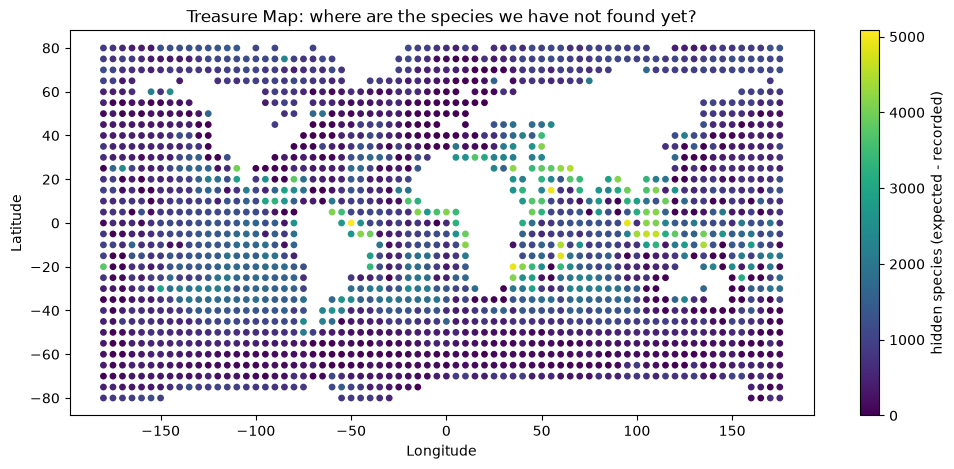

In [63]:
plt.figure(figsize=(12, 5))
plt.scatter(grid["cell_lon"], grid["cell_lat"], c=grid["hidden_species"], cmap="viridis", s=15)
plt.colorbar(label="hidden species (expected - recorded)")
plt.title("Treasure Map: where are the species we have not found yet?")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

In [64]:
#8.2 risk today: feed each NOAA station's last day into Model 2
heat["date"] = pd.to_datetime(heat[["year", "month", "day"]])
today = heat.sort_values("date").groupby("station").tail(1).merge(stations, on="station").reset_index(drop=True)

#site columns = median of bleaching surveys within 300 km (or the world median)
site_cols = ["ClimSST", "Depth_m", "Distance_to_Shore", "Turbidity", "Cyclone_Frequency", "Windspeed"]
near_samples = bleach_tree.query_radius(np.radians(today[["lat", "lon"]]), r=300 / EARTH_KM)
site_values = pd.DataFrame([df.iloc[i][site_cols].median() if len(i) > 0 else df[site_cols].median()
                            for i in near_samples])

#heat columns from NOAA (Kelvin = °C + 273.15)
X_today = pd.DataFrame({
    "Temperature_Kelvin": today["sst"] + 273.15,
    "SSTA": today["sst_anomaly"],
    "TSA": today["sst"] - today["max_monthly_mean_sst"],
    "SSTA_DHW": today["dhw"],
    "TSA_DHW": today["dhw"],
    "Date_Month": today["date"].dt.month})
X_today = pd.concat([X_today, site_values], axis=1)[CURRENT]

today["severe_risk"] = model2.predict_proba(X_today)[:, 2]
today["risk_class"] = model2.predict(X_today)

print("Date:", today["date"].max().date())
print("Stations with bleaching surveys within 300 km:", sum(len(i) > 0 for i in near_samples), "of", len(today))
print("Regions predicted 'severe':", (today["risk_class"] == 2).sum(), "of", len(today))
today.sort_values("severe_risk", ascending=False)[["station", "sst", "dhw", "severe_risk"]].head(10).round(2)

Date: 2026-11-10
Stations with bleaching surveys within 300 km: 179 of 214
Regions predicted 'severe': 65 of 214


,station,sst,dhw,severe_risk
210,"Phoenix Islands, Kiribati",30.08,13.67,0.86
126,Southern Line Islands,30.45,19.04,0.83
176,Northern Myanmar,30.74,8.98,0.77
47,Leeward Caribbean Islands,29.62,15.85,0.76
107,Northeastern Cuba,29.51,13.15,0.75
63,Cape Verde Islands,29.24,17.14,0.75
151,Virgin Islands,29.80,15.19,0.75
208,Puerto Rico,29.80,13.89,0.74
213,Yucatan Peninsula,28.18,18.11,0.73
179,Northern Line Islands,29.77,26.85,0.71


In [65]:
#8.3 Treasures at Risk = rank of hidden species (Model 1) × rank of severe risk today (Model 2)
#each station -> the nearest ocean cell
cell_tree = BallTree(np.radians(grid[["cell_lat", "cell_lon"]]), metric="haversine")
_, cell = cell_tree.query(np.radians(today[["lat", "lon"]]), k=1)
today["hidden_species"] = grid["hidden_species"].to_numpy()[cell[:, 0]]

today["treasure_at_risk"] = (today["hidden_species"].rank(pct=True) * today["severe_risk"].rank(pct=True) * 100).round(1)
today["rank"] = today["treasure_at_risk"].rank(ascending=False, method="min").astype(int)
today.sort_values("treasure_at_risk", ascending=False)[
    ["station", "hidden_species", "severe_risk", "dhw", "treasure_at_risk"]].head(10).round(2)

,station,hidden_species,severe_risk,dhw,treasure_at_risk
176,Northern Myanmar,3966.0,0.77,8.98,90.0
102,"Dhofar, Oman",4926.0,0.55,4.56,87.4
117,Southwestern Cuba,3800.0,0.66,10.61,84.0
2,"Jazan, Saudi Arabia",3295.0,0.62,17.52,76.6
89,Egypt,4224.0,0.43,8.83,73.0
71,Bahrain,3821.0,0.48,6.12,71.3
87,Eritrea,3295.0,0.51,12.39,68.4
9,Honduras,2906.0,0.53,10.34,68.0
32,Nicaragua,2485.0,0.68,11.35,66.8
1,Western Yemen,3295.0,0.46,12.14,66.4


In [66]:
#8.4 Red Sea spotlight: our 3 Saudi regions today
saudi = ["Tabuk, Saudi Arabia", "Al Madinah and Makkah", "Jazan, Saudi Arabia"]
today[today["station"].isin(saudi)][
    ["station", "sst", "dhw", "severe_risk", "hidden_species", "treasure_at_risk", "rank"]].round(2)

,station,sst,dhw,severe_risk,hidden_species,treasure_at_risk,rank
2,"Jazan, Saudi Arabia",32.04,17.52,0.62,3295.0,76.6,4
45,Al Madinah and Makkah,32.22,14.01,0.54,2199.0,56.9,24
110,"Tabuk, Saudi Arabia",29.70,4.01,0.34,4224.0,64.0,13


In [67]:
#8.5 Dive Finder (Reef Health Index)

#1- add today's risk from the nearest NOAA station (Model 2)
dive_sites = dive_sites.merge(today[["station", "severe_risk"]], on="station", how="left")

#2- every part -> percentile 0-100 (high = good), missing -> 50 (neutral)
def pct_score(col, higher_is_better=True):
    p = col.rank(pct=True) * 100
    if not higher_is_better:
        p = 100 - p
    return p.fillna(50)

dive_sites["s_fish"] = pct_score(dive_sites["fish_species"])
dive_sites["s_coral"] = pct_score(dive_sites["hard_coral"])
dive_sites["s_visibility"] = pct_score(dive_sites["visibility"])
dive_sites["s_low_risk"] = pct_score(dive_sites["severe_risk"], higher_is_better=False)
dive_sites["s_low_bleach"] = pct_score(dive_sites["bleach_history"], higher_is_better=False)

In [68]:
#3- weighted score
WEIGHTS = {"s_fish": 0.30, "s_coral": 0.25, "s_visibility": 0.15, "s_low_risk": 0.15, "s_low_bleach": 0.15}

def health_index(data, weights):
    return sum(data[col] * w for col, w in weights.items())

dive_sites["health_index"] = health_index(dive_sites, WEIGHTS).round(1)
dive_sites.sort_values("health_index", ascending=False)[
    ["site_name", "country", "dives", "fish_species", "hard_coral", "visibility",
     "severe_risk", "bleach_history", "health_index"]].head(10).round(2)

,site_name,country,dives,fish_species,hard_coral,visibility,severe_risk,bleach_history,health_index
10,West White Beach,Australia,3,59.00,70.00,30.00,0.09,1.59,93.6
7,Flying Fish Cove Boat Ramp,Australia,6,62.00,53.33,18.25,0.09,1.59,90.9
2226,South Pasar Sari Gosong Bone Atoll,Indonesia,3,75.00,59.00,20.00,0.04,NaN,87.7
2225,Taat Pulau Besar,Indonesia,3,76.33,46.00,28.00,0.04,NaN,87.6
2239,Manta Cay,Indonesia,3,74.00,54.00,21.33,NaN,0.50,87.4
2234,Ransiwor Islet,Indonesia,3,98.67,43.67,26.00,NaN,0.50,87.2
2242,Fam Slope,Indonesia,5,85.60,45.25,24.00,NaN,0.50,87.0
438,North Island Site 3,Australia,6,58.17,87.00,21.67,0.10,9.31,86.9
2240,Cape Kri,Indonesia,4,118.00,34.75,31.25,NaN,0.50,86.3
357,Blackwood Shoal,Australia,4,59.00,51.00,27.50,0.04,NaN,86.1


In [69]:
#4- is the ranking stable when the weights change?
other_weights = {
    "equal": {k: 0.20 for k in WEIGHTS},
    "more fish": {"s_fish": 0.40, "s_coral": 0.20, "s_visibility": 0.10, "s_low_risk": 0.15, "s_low_bleach": 0.15},
    "more danger": {"s_fish": 0.20, "s_coral": 0.20, "s_visibility": 0.10, "s_low_risk": 0.25, "s_low_bleach": 0.25},
    "no visibility": {"s_fish": 0.35, "s_coral": 0.30, "s_visibility": 0.00, "s_low_risk": 0.175, "s_low_bleach": 0.175}}

top10 = set(dive_sites.nlargest(10, "health_index")["site_code"])
rows = []
for name, w in other_weights.items():
    other = health_index(dive_sites, w)
    same_top10 = len(top10 & set(dive_sites.loc[other.nlargest(10).index, "site_code"]))
    rows.append([name, dive_sites["health_index"].corr(other, method="spearman"), same_top10])

pd.DataFrame(rows, columns=["weights", "Spearman", "same top 10"]).round(3)

,weights,Spearman,same top 10
0,equal,0.976,7
1,more fish,0.989,8
2,more danger,0.957,6
3,no visibility,0.963,7


In [70]:
#5- endangered animals near each site + the demo site
counts = threatened.pivot_table(index="site_code", columns="category", values="species", aggfunc="nunique", fill_value=0)
dive_sites = dive_sites.merge(counts, left_on="site_code", right_index=True, how="left")
dive_sites[["CR", "EN", "VU"]] = dive_sites[["CR", "EN", "VU"]].fillna(0).astype(int)
dive_sites["rank"] = dive_sites["health_index"].rank(ascending=False, method="min").astype(int)

dive_sites[dive_sites["site_name"] == "Ransiwor Islet"][
    ["site_name", "country", "fish_species", "hard_coral", "visibility", "health_index", "rank", "CR", "EN", "VU"]].round(1)

,site_name,country,fish_species,hard_coral,visibility,health_index,rank,CR,EN,VU
2234,Ransiwor Islet,Indonesia,98.7,43.7,26.0,87.2,6,4,49,32


### Results and Interpretation

1. **Treasure Map:** Warm cells have more estimated hidden species (median 1,075 vs 400 in cold cells). High-ranking areas include the western Indian Ocean and Arabian Sea, Java Sea, and waters off the Amazon.

2. **Risk Today (10 Nov 2026):** 65 of 214 reef regions are predicted severe. NOAA's daily DHW differs slightly from the database measure, so this is an estimate. Of 214 stations, 179 have bleaching surveys within 300 km; the other 35 use the world median for site features.

3. **Treasures at Risk:** The score multiplies the hidden-species rank by the severe-risk rank, prioritizing places high in both. Top areas: Northern Myanmar, Dhofar (Oman), Southwestern Cuba, and Jazan (#4 overall; #1 in Saudi Arabia and the Red Sea, with 62% severe risk and DHW 17.5).

4. **Red Sea:** Jazan is currently at risk, but Red Sea corals show less severe bleaching under strong heat (2.1% vs 56.4%). This may indicate a coral refuge; the comparison is based mostly on northern data.

5. **Dive Finder:** This is a score, not a predictive model, because no "good site" label exists. Percentiles put fish, coral, visibility, and risk on a 0–100 scale; missing values receive a neutral score of 50. Rankings are stable (Spearman 0.96–0.99); 6–8 of the top 10 sites remain the same across alternative weights.

6. **Demo:** Ransiwor Islet (Raja Ampat) ranks #6 of 2,648 sites, with four critically endangered species nearby, including the hawksbill turtle.

In [71]:
OUT = "../outputs/" if os.path.exists("../datasets_csv") else "outputs/"
MODELS = "../models/" if os.path.exists("../datasets_csv") else "models/"
os.makedirs(OUT, exist_ok=True)
os.makedirs(MODELS, exist_ok=True)

#2 models (~13 MB and ~30 MB)
joblib.dump(model1, MODELS + "model1_treasure_map.joblib", compress=3)
joblib.dump(model2, MODELS + "model2_bleaching_risk.joblib", compress=3)

#clean tables for the app
grid.to_csv(OUT + "treasure_map.csv", index=False)
today.to_csv(OUT + "risk_today.csv", index=False)
dive_sites.to_csv(OUT + "dive_finder.csv", index=False)

#results for the "How we know" boxes
results1.join(sanity).to_csv(OUT + "results_model1.csv")
results2.to_csv(OUT + "results_model2.csv")
compare.to_csv(OUT + "results_future_test.csv")
final.to_csv(OUT + "results_final.csv", index=False)

print("Saved:", os.listdir(OUT), os.listdir(MODELS))

Saved: ['dive_finder.csv', 'results_final.csv', 'results_future_test.csv', 'results_model1.csv', 'results_model2.csv', 'risk_today.csv', 'treasure_map.csv'] ['model1_treasure_map.joblib', 'model2_bleaching_risk.joblib']


In [72]:
#station inputs for the live app (everything except today's heat)
station_inputs = pd.concat([today[["station", "lat", "lon", "max_monthly_mean_sst", "hidden_species"]], site_values], axis=1)
station_inputs.to_csv(OUT + "station_inputs.csv", index=False)